# 가게는 많은데, 선택지는?
## 2025년 서울 행정동별 점포 밀도와 업종 다양성
연구 질문: 점포가 조밀한 동네는 업종 구성도 다양한가?
수업의 Density, Entropy를 사용하고 LQ를 보조지표로 계산합니다. 각 셀을 위에서부터 실행하세요. 원본은 source_data/에 보존되어 있습니다.

In [2]:
from pathlib import Path
import sys, math
import pandas as pd
root = Path.cwd()
if not (root / 'scripts').exists():
    raise RuntimeError('seoul_store_atlas 폴더에서 이 노트북을 실행하세요.')
sys.path.insert(0, str(root / 'scripts'))
from build_analysis import read_sources, analyze, diversity, main
stores, boundary = read_sources()
stores.head()

,기준_년분기_코드,행정동_코드,행정동_코드_명,서비스_업종_코드,서비스_업종_코드_명,점포_수,유사_업종_점포_수,개업_율,개업_점포_수,폐업_률,폐업_점포_수,프랜차이즈_점포_수
0,20251,11110515,청운효자동,CS100001,한식음식점,79,79,3,2,1,1,0
1,20251,11110515,청운효자동,CS100002,중식음식점,2,2,0,0,0,0,0
2,20251,11110515,청운효자동,CS100003,일식음식점,15,15,0,0,7,1,0
3,20251,11110515,청운효자동,CS100004,양식음식점,54,54,2,1,0,0,0
4,20251,11110515,청운효자동,CS100005,제과점,19,20,0,0,0,0,1


## 1. 분기와 중복 확인
자료 한 행은 분기 × 행정동 × 업종입니다. 4개 분기의 점포 수는 같은 점포를 반복 관측한 재고이므로 더하지 않습니다. 아래에서 분기를 하나 선택합니다.

In [3]:
print(stores.groupby('기준_년분기_코드')['행정동_코드'].nunique())
print('중복:', stores.duplicated(['기준_년분기_코드','행정동_코드','서비스_업종_코드']).sum())
quarter = 20254
current = stores[stores['기준_년분기_코드'] == quarter].copy()
current.shape

기준_년분기_코드
20251    425
20252    425
20253    425
20254    425
Name: 행정동_코드, dtype: int64
중복: 0


(35317, 12)

## 2. 어떤 점포 수를 사용할까?
이 원본에서 유사_업종_점포_수 = 점포_수 + 프랜차이즈_점포_수인지 검증합니다. 전체 점포는 유사_업종_점포_수 하나만 사용합니다.

In [4]:
identity = stores['유사_업종_점포_수'] == stores['점포_수'] + stores['프랜차이즈_점포_수']
print('모든 행에서 일치:', identity.all())
print('선택 분기의 전체 점포:', current['유사_업종_점포_수'].sum())

모든 행에서 일치: True
선택 분기의 전체 점포: 632830


## 3. 한 동의 점포 밀도 직접 계산
D = N / A. N은 점포 수(개), A는 원본 도형에서 구한 면적(㎢)입니다. 미터 단위 투영좌표계에서 면적을 구해야 합니다.

In [5]:
code = current.loc[current['행정동_코드_명'] == '신당동', '행정동_코드'].iloc[0]
one = current[current['행정동_코드'] == code]
total = int(one['유사_업종_점포_수'].sum())
area = float(boundary.loc[boundary['ADSTRD_CD'] == code, 'area_km2'].iloc[0])
density = total / area
print('점포 수:', total, '면적:', area, '밀도:', density)

점포 수: 10107 면적: 0.534941537685648 밀도: 18893.653395708556


## 4. 같은 동의 다양성 직접 계산
p는 해당 동의 전체 점포 중 업종별 비율입니다. H = -Σ(p ln p)/ln(100). 모든 동의 업종 수를 100개로 고정합니다. 없는 업종의 항은 0입니다. 값이 높으면 구성 비율이 고릅니다.

In [6]:
industry_codes = sorted(stores['서비스_업종_코드'].unique())
counts = one.set_index('서비스_업종_코드')['유사_업종_점포_수'].reindex(industry_codes, fill_value=0)
entropy = 0
for count in counts:
    if count > 0:
        p = count / total
        entropy -= p * math.log(p)
normalized_entropy = entropy / math.log(100)
print('정규화 Entropy:', normalized_entropy)
assert abs(normalized_entropy - diversity(counts.tolist())) < 1e-10

정규화 Entropy: 0.185917635095016


## 5. 전체 동에 적용하고 두 지표 비교
분석 함수는 위 계산을 각 분기·행정동에 반복합니다. 상권과 지도의 행정동 코드 425개가 모두 대응하는지 확인한 뒤 계산합니다. 지도용 단순화 이전의 면적을 사용합니다.

In [7]:
data, results = analyze(stores, boundary)
selected = results[results['quarter'] == quarter]
display(selected.sort_values('density', ascending=False).head(10))
print('밀도 중앙값:', selected['density'].median())
print('다양성 중앙값:', selected['entropy'].median())
print('피어슨 상관:', selected['density'].corr(selected['entropy']))
print('스피어만 순위 상관:', selected['density'].rank().corr(selected['entropy'].rank()))

,quarter,code,name,district,area,total,density,entropy,type,active,top,topShare,topLq
1299,20254,11140615,신당동,중구,0.534942,10107,18893.653396,0.185918,1,88,67,0.869991,11.845528
1297,20254,11140590,광희동,중구,0.737204,5116,6939.737639,0.632804,1,93,67,0.417905,5.690059
1642,20254,11680630,대치4동,강남구,0.701081,4123,5880.915248,0.760421,1,96,10,0.211254,5.114692
1293,20254,11140540,회현동,중구,0.897827,4987,5554.522660,0.598972,1,85,67,0.433126,5.897311
1489,20254,11440660,서교동,마포구,1.678981,8820,5253.187364,0.822467,0,98,0,0.097392,1.046006
1287,20254,11110670,창신1동,종로구,0.305337,1586,5194.255461,0.625981,1,77,70,0.344893,52.567081
1643,20254,11680640,역삼1동,강남구,2.362133,12035,5094.971219,0.830361,0,99,42,0.099709,1.695161
1294,20254,11140550,명동,중구,0.969729,4797,4946.740702,0.768034,1,90,53,0.126120,11.822372
1298,20254,11140605,을지로동,중구,0.611524,2983,4877.976268,0.737893,1,91,67,0.163929,2.232005
1283,20254,11110615,종로1·2·3·4가동,종로구,2.417171,10387,4297.171751,0.714501,1,95,73,0.240589,26.075023


밀도 중앙값: 1215.432409
다양성 중앙값: 0.8206871
피어슨 상관: -0.4457544926470251
스피어만 순위 상관: 0.09170624189085679


## 6. 지도와 산점도
네 유형의 높고 낮음은 해당 분기 서울 중앙값 이상/미만입니다. 고밀도·저다양성이 나쁜 상권을 뜻하지는 않습니다. 그래프의 극단값과 최다 업종 구성을 함께 살펴보세요.

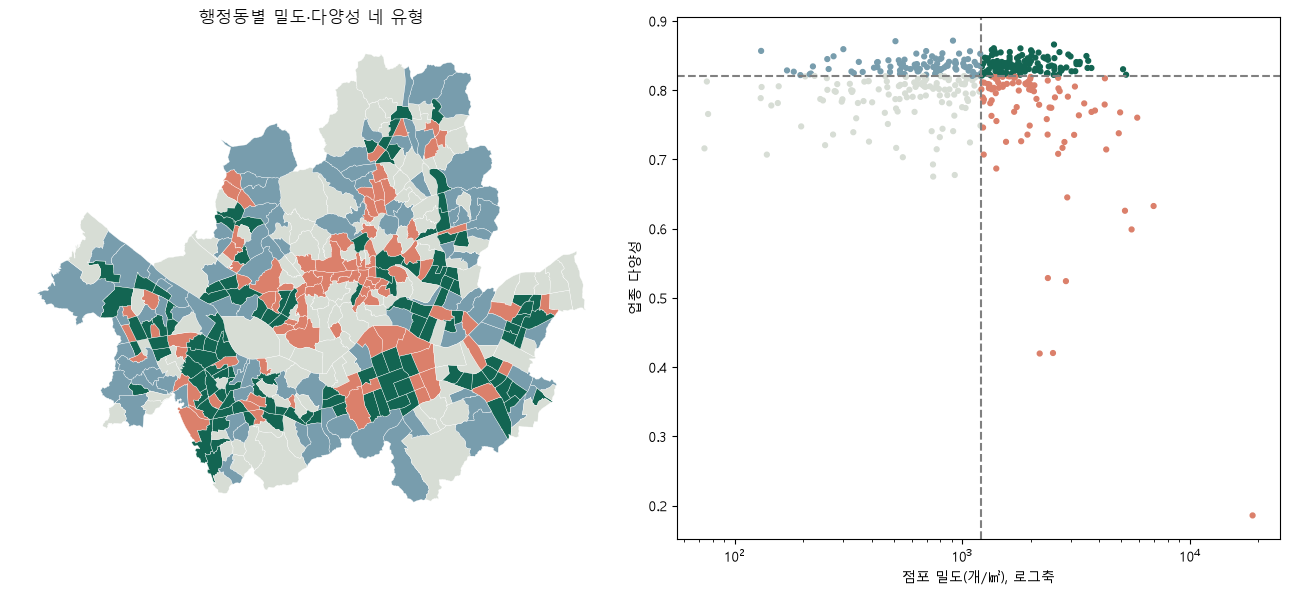

In [8]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
plt.rcParams['font.family'] = 'Malgun Gothic' if any(f.name == 'Malgun Gothic' for f in font_manager.fontManager.ttflist) else 'DejaVu Sans'
joined = boundary.merge(selected, left_on='ADSTRD_CD', right_on='code', validate='one_to_one')
colors = ['#136552','#db806b','#789dad','#d7ddd5']
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
joined.plot(color=[colors[int(t)] for t in joined['type']], edgecolor='white', linewidth=0.25, ax=axes[0])
axes[0].set_title('행정동별 밀도·다양성 네 유형'); axes[0].set_axis_off()
axes[1].scatter(selected['density'], selected['entropy'], c=[colors[int(t)] for t in selected['type']], s=12)
axes[1].set_xscale('log'); axes[1].set_xlabel('점포 밀도(개/㎢), 로그축'); axes[1].set_ylabel('업종 다양성')
axes[1].axvline(selected['density'].median(), color='gray', linestyle='--')
axes[1].axhline(selected['entropy'].median(), color='gray', linestyle='--')
plt.tight_layout(); plt.show()

## 7. 웹앱 자료와 보고서 저장
결과는 dist/data/와 docs/에 저장됩니다. 전체 업종 구성은 실제 체감 선택권의 대리지표일 뿐이며 매장 품질·매출·영업시간·접근성을 직접 측정하지 않습니다. 산지·하천이 포함된 면적과 과거 명칭을 쓰는 상권 경계의 영향도 설명합니다.

In [9]:
main()

{
  "audit": {
    "rawRows": 141218,
    "duplicateRows": 0,
    "missingCounts": 0,
    "mappedDongs": 425,
    "industryCount": 100,
    "source": "https://data.seoul.go.kr/dataList/OA-22172/S/1/datasetView.do",
    "boundarySource": "https://data.seoul.go.kr/dataList/OA-22160/S/1/datasetView.do",
    "sourceSha256": "1eb65713ac04861ac54a765984e9a9072e55288fd1c715409f3cce22782d2e69",
    "boundarySha256": "969f7033bd3609a5fd586790f5b2cfedc638d7647ef45c78f9c75e1dabf79f68"
  },
  "q4": {
    "total": 632830,
    "medianDensity": 1215.432408704389,
    "medianEntropy": 0.8206871028617391,
    "typeCounts": [
      120,
      93,
      93,
      119
    ],
    "pearson": -0.4457544932384358,
    "spearman": 0.09170624189085679
  }
}
